In [5]:
import logging, warnings
import numpy as np, pandas as pd
from pathlib import Path
from scipy.stats import spearmanr, ConstantInputWarning
from tqdm import tqdm
from umap import UMAP
from dtaidistance import dtw, dtw_visualisation as dtwvis
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt
import pathlib
import importlib
import sys

import os
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ.get("PATH", "")


from mtsspi.utils import iter_dataset_dirs, load_json
from mtsspi.plot_style import apply_plot_style
from mtsspi.visualization import plot_mts_corr_density, plot_spi_space_individual, plot_pca, plot_tsne, plot_umap, plot_mts_heatmap
from mtsspi.utils import project_root
import numpy as np
import pandas as pd
from mtsspi.utils import project_root
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import plot_pca, plot_umap, plot_tsne, plot_spi_space_individual, plot_spi_space_recursive

apply_plot_style()
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
warnings.simplefilter("ignore", ConstantInputWarning)


#### @ Mon 13-Apr: refactoring the case generator: `generate_lagged_warping_mts()`

##### Results from refactoring `xpdist_*` to not cheat on initial stutters relative to `dtw`

In [21]:
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import (plot_spi_space_individual_embed,
                                plot_spi_space_individual_embed_properties, 
                                plot_spi_space_individual_embed_lags
                                )

from mtsspi.plot_style import apply_plot_style
import matplotlib.pyplot as plt

apply_plot_style()

spi_pairs = [
    ["pdist_euclidean_rmse", "xpdist_euclidean_tau-10_min_rmse"],
    ["pdist_euclidean_rmse", "dtw_rmse"],
    ["dtw_rmse", "xpdist_euclidean_tau-10_min_rmse"],
]

base = "data/dtw_euclidean/260413_2_lagged-warping_rmse_T1000/"

datasets = [
    f"{base}/pstep-0.0_maxlag-0/M20_T1000_I0",
    f"{base}/pstep-0.0_maxlag-5/M20_T1000_I0",
    f"{base}/pstep-0.1_maxlag-5/M20_T1000_I0",
    f"{base}/pstep-0.3_maxlag-5/M20_T1000_I0",
    f"{base}/pstep-0.5_maxlag-5/M20_T1000_I0",
    f"{base}/pstep-0.7_maxlag-5/M20_T1000_I0",
    f"{base}/pstep-0.9_maxlag-5/M20_T1000_I0",
]

n_rows, n_cols = len(datasets), len(spi_pairs)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), 
                         squeeze=False, dpi=500)

for r, ds in enumerate(datasets):
    for c, spis in enumerate(spi_pairs):
        plot_spi_space_individual_embed_lags(
            dataset_path=project_root() / ds,
            spis=spis,
            ax=axes[r, c],
            lag_feature="diff",   # |tau_i - tau_j|
            alpha=0.5,
            metric="pearson",
            identity=True
        )

fig.tight_layout(w_pad=7, h_pad=2)
plt.show()


/var/folders/nq/8y70t4y10yb6nq4v5m7p_j340000gp/T/ipykernel_25384/230295246.py:47: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(w_pad=7, h_pad=2)


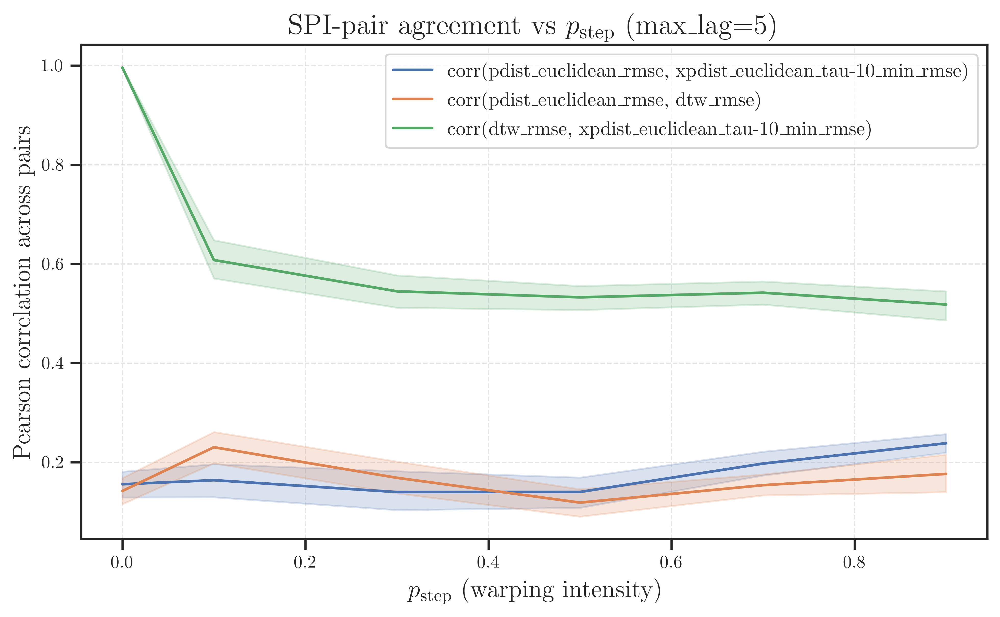

In [25]:
# corr(spi_x, spi_y) vs p_step — all three pairs on one axis
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import plot_spi_corr_sweep
from mtsspi.plot_style import apply_plot_style
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

apply_plot_style()

spi_pairs = [
    ["pdist_euclidean_rmse", "xpdist_euclidean_tau-10_min_rmse"],
    ["pdist_euclidean_rmse", "dtw_rmse"],
    ["dtw_rmse", "xpdist_euclidean_tau-10_min_rmse"],
]

dataset_root = project_root() / "data" / "dtw_euclidean" / "260413_2_lagged-warping_rmse_T1000"

frames = []
for pair in spi_pairs:
    fig_tmp, ax_tmp = plt.subplots()
    df = plot_spi_corr_sweep(
        dataset_root,
        spi_pair=pair,
        folder_template="pstep-<pstep>_maxlag-5",
        x_var="pstep",
        metric="pearson",
        hue=False,
        ax=ax_tmp,
    )
    plt.close(fig_tmp)
    df = df.copy()
    df["pair"] = f"corr({pair[0]}, {pair[1]})"
    frames.append(df)

combined = pd.concat(frames, ignore_index=True)

fig, ax = plt.subplots(figsize=(8, 5), dpi=500)
ax.grid(True, which="both", axis="both", lw=0.7, linestyle="--", alpha=0.5)
sns.lineplot(
    data=combined,
    x="x",
    y="correlation",
    hue="pair",
    ax=ax,
    errorbar=("ci", 95),
    err_style="band",
)
ax.set_xlabel(r"$p_{\mathrm{step}}$ (warping intensity)")
ax.set_ylabel(r"Pearson correlation across pairs")
ax.set_title(r"SPI-pair agreement vs $p_{\mathrm{step}}$ (max_lag=5)")
ax.legend(loc="best", frameon=True)
fig.tight_layout()
plt.show()


##### Sanity check: zero-mean property.

**CLAIM:** rebound L excursions, when collapsed by _path_to_mapping into stutter/plateau patterns, must still be zero-mean *relative to xpdist*. What xpdist actually optimises over is a single global shift between two channels, so the relevant invariant is per-PAIR relative offset (mapping_i[t] - mapping_j[t]) averaged over t and over pairs — not per channel in isolation.

**EMPIRICAL FINDING:** per-channel  E[m_i(t) - t]  ≈ -0.56  (NOT zero — bias from round() + maximum.accumulate in _path_to_mapping) per-pair    E[m_i(t) - m_j(t)]  ≈  0   (cancels exactly — what xpdist sees)

**Verdict:** xpdist's optimal global shift on a pair recovers the relative lag (Δτ_ij) without warp contamination. The case study is sound.

channel 18: tau=5
  offset support     [-4, 2]
  offset mean        -0.5360   (per-channel — biased, see relative below)
  offset std         1.2036
  plateau frac (emp) 0.515
  plateau frac (theo)  0.500


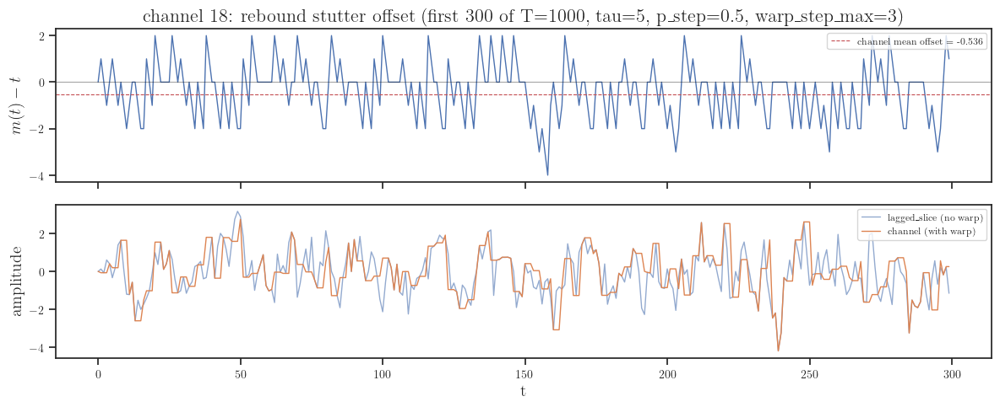


over 30 seeds × 20 channels = 600 samples:
  per-channel  E[m_i(t) - t]:           mean = -0.5571, std = 0.0673   <-- BIASED
  per-pair    E[m_i(t) - m_j(t)]:       mean = +0.0012, std = 0.0933   <-- ZERO  (xpdist sees this)

=> rebound bias is uniform across channels; cancels in pair differences.

p_step sweep (theoretical plateau fraction, fixed s = 3):
  p_step = 0.0  ->  plateau_frac = 0.000
  p_step = 0.1  ->  plateau_frac = 0.167
  p_step = 0.3  ->  plateau_frac = 0.375
  p_step = 0.5  ->  plateau_frac = 0.500
  p_step = 0.7  ->  plateau_frac = 0.583
  p_step = 0.9  ->  plateau_frac = 0.643


In [ ]:
import importlib
import numpy as np
import matplotlib.pyplot as plt
import mtsspi.generators.linear
importlib.reload(mtsspi.generators.linear)
from mtsspi.generators.linear import generate_lagged_warping_mts
from mtsspi.plot_style import apply_plot_style

apply_plot_style()

# --- Single channel: visualise the stutter offset trajectory ---
M, T = 20, 1000
max_lag = 5
warp_step_max = 3
p_step = 0.5

data, internals = generate_lagged_warping_mts(
    M=M, T=T,
    max_lag=max_lag, lag_dist="linspace",
    p_step=p_step, warp_step_dist="fixed", warp_step_max=warp_step_max,
    noise_std=0.0,
    noise_std_variable=False,
    ar1_a=0.5, ar1_noise_std=1.0,
    zscore=False,
    rng=np.random.default_rng(0),
    return_internals=True,
)

ch = int(np.argmax(internals.lags))
mapping = internals.mappings[ch]
tau = int(internals.lags[ch])
offset = mapping - np.arange(T)
plateau_emp = (np.diff(mapping) == 0).mean()
s = warp_step_max
plateau_theo = p_step * (s - 1) / ((1 - p_step) + p_step * s)
print(f"channel {ch}: tau={tau}")
print(f"  offset support     [{offset.min():d}, {offset.max():d}]")
print(f"  offset mean        {offset.mean():+.4f}   (per-channel — biased, see relative below)")
print(f"  offset std         {offset.std():.4f}")
print(f"  plateau frac (emp) {plateau_emp:.3f}")
print(f"  plateau frac (theo)  {plateau_theo:.3f}")

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(np.arange(T)[:300], offset[:300], lw=1.0)
axes[0].axhline(0.0, color="k", lw=0.6, alpha=0.5)
axes[0].axhline(offset.mean(), color="C3", lw=0.8, ls="--",
                label=f"channel mean offset = {offset.mean():+.3f}")
axes[0].set_ylabel(r"$m(t) - t$")
axes[0].legend(loc="upper right", fontsize=8)
axes[0].set_title(
    f"channel {ch}: rebound stutter offset (first 300 of T={T}, "
    f"tau={tau}, p_step={p_step}, warp_step_max={warp_step_max})"
)

mother = internals.mother
lagged_slice = mother[max_lag - tau : max_lag - tau + T]
axes[1].plot(lagged_slice[:300], lw=1.0, alpha=0.6, label="lagged_slice (no warp)")
axes[1].plot(data[:300, ch], lw=1.0, label="channel (with warp)")
axes[1].set_xlabel("t")
axes[1].set_ylabel("amplitude")
axes[1].legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

# --- Per-channel vs per-pair statistics over many seeds ---
n_seeds = 30
per_channel_means = []
per_pair_relative_means = []
for seed in range(n_seeds):
    _, ints = generate_lagged_warping_mts(
        M=M, T=T,
        max_lag=max_lag, lag_dist="linspace",
        p_step=p_step, warp_step_dist="fixed", warp_step_max=warp_step_max,
        noise_std=0.0, noise_std_variable=False,
        ar1_a=0.5, ar1_noise_std=1.0, zscore=False,
        rng=np.random.default_rng(seed), return_internals=True,
    )
    maps = np.array(ints.mappings)  # (M, T)
    per_channel_means.extend((maps - np.arange(T)).mean(axis=1))
    for i in range(M):
        for j in range(i + 1, M):
            per_pair_relative_means.append((maps[i] - maps[j]).mean())

pcm = np.array(per_channel_means)
ppm = np.array(per_pair_relative_means)
print()
print(f"over {n_seeds} seeds × {M} channels = {len(pcm)} samples:")
print(f"  per-channel  E[m_i(t) - t]:           "
      f"mean = {pcm.mean():+.4f}, std = {pcm.std():.4f}   <-- BIASED")
print(f"  per-pair    E[m_i(t) - m_j(t)]:       "
      f"mean = {ppm.mean():+.4f}, std = {ppm.std():.4f}   <-- ZERO  (xpdist sees this)")
print()
print("=> rebound bias is uniform across channels; cancels in pair differences.")

# --- p_step sweep: theoretical plateau fractions for fixed s = warp_step_max ---
print()
print(f"p_step sweep (theoretical plateau fraction, fixed s = {warp_step_max}):")
for ps in [0.0, 0.1, 0.3, 0.5, 0.7, 0.9]:
    f = ps * (s - 1) / ((1 - ps) + ps * s) if ps > 0 else 0.0
    print(f"  p_step = {ps:.1f}  ->  plateau_frac = {f:.3f}")

##### Results from refactored generator

In [18]:
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import (plot_spi_space_individual_embed,
                                plot_spi_space_individual_embed_properties, 
                                plot_spi_space_individual_embed_lags
                                )

from mtsspi.plot_style import apply_plot_style
import matplotlib.pyplot as plt

apply_plot_style()

spi_pairs = [
    ["pdist_euclidean_rmse", "xpdist_euclidean_tau-10_min_rmse"],
    ["pdist_euclidean_rmse", "dtw_rmse"],
    ["dtw_rmse", "xpdist_euclidean_tau-10_min_rmse"],
]

base = "data/dtw_euclidean/260413_lagged-warping_rmse_T1000/"

datasets = [
    f"{base}/pstep-0.0_maxlag-0/M20_T1000_I0",
    f"{base}/pstep-0.0_maxlag-5/M20_T1000_I0",
    f"{base}/pstep-0.1_maxlag-5/M20_T1000_I0",
    f"{base}/pstep-0.3_maxlag-5/M20_T1000_I0",
    f"{base}/pstep-0.5_maxlag-5/M20_T1000_I0",
    f"{base}/pstep-0.7_maxlag-5/M20_T1000_I0",
    f"{base}/pstep-0.9_maxlag-5/M20_T1000_I0",
]

n_rows, n_cols = len(datasets), len(spi_pairs)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), 
                         squeeze=False, dpi=500)

for r, ds in enumerate(datasets):
    for c, spis in enumerate(spi_pairs):
        plot_spi_space_individual_embed_lags(
            dataset_path=project_root() / ds,
            spis=spis,
            ax=axes[r, c],
            lag_feature="diff",   # |tau_i - tau_j|
            alpha=0.5,
            metric="pearson",
            identity=True
        )

fig.tight_layout(w_pad=7, h_pad=2)
plt.show()


/var/folders/nq/8y70t4y10yb6nq4v5m7p_j340000gp/T/ipykernel_25384/3762574261.py:47: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(w_pad=7, h_pad=2)





In [24]:
# corr(spi_x, spi_y) vs p_step sweep
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import plot_spi_corr_sweep
from mtsspi.plot_style import apply_plot_style
import matplotlib.pyplot as plt

apply_plot_style()

spi_pairs = [
    ["pdist_euclidean_rmse", "xpdist_euclidean_tau-10_min_rmse"],
    ["pdist_euclidean_rmse", "dtw_rmse"],
    ["dtw_rmse", "xpdist_euclidean_tau-10_min_rmse"],
]

fig, axes = plt.subplots(1, len(spi_pairs), figsize=(7 * len(spi_pairs), 4), squeeze=False, sharey=True, dpi=500)

for ax, spi_pair in zip(axes.flat, spi_pairs):
    ax.grid(True, which="both", axis="both", lw=0.7, linestyle="--", alpha=0.5)
    plot_spi_corr_sweep(
        project_root() / "data" / "dtw_euclidean" / "260413_2_lagged-warping_rmse_T1000",
        spi_pair=spi_pair,
        folder_template="pstep-<pstep>_maxlag-5",
        x_var="pstep",
        metric="pearson",
        hue=False,
        title=rf"corr({spi_pair[0]}, {spi_pair[1]}) vs p_step",
        xlabel=r"$p_{\mathrm{step}}$ (warping intensity)",
        ylabel=rf"$\mathrm{{corr}}$({spi_pair[0]}, {spi_pair[1]})",
        ax=ax,
    )

fig.tight_layout()
plt.show()

#### @ Sun 12-Apr: changed `xpdist_*` to have `tau-10` where MTS generator has `max_lag: 5`

In [ ]:
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import (plot_spi_space_individual_embed,
                                plot_spi_space_individual_embed_properties, 
                                plot_spi_space_individual_embed_lags
                                )

from mtsspi.plot_style import apply_plot_style
import matplotlib.pyplot as plt

apply_plot_style()

spi_pairs = [
    ["pdist_euclidean_rmse", "xpdist_euclidean_tau-10_min_rmse"],
    ["pdist_euclidean_rmse", "dtw_rmse"],
    ["dtw_rmse", "xpdist_euclidean_tau-10_min_rmse"],
]

base = "data/dtw_euclidean/260412_lagged-warping_rmse_T1000/"

datasets = [
    f"{base}/lag-5_pstep-0.0/M20_T1000_I0",
    f"{base}/lag-5_pstep-0.1/M20_T1000_I0",
    f"{base}/lag-5_pstep-0.3/M20_T1000_I0",
    f"{base}/lag-5_pstep-0.5/M20_T1000_I0",
    f"{base}/lag-5_pstep-0.7/M20_T1000_I0",
    f"{base}/lag-5_pstep-0.9/M20_T1000_I0",
]

n_rows, n_cols = len(datasets), len(spi_pairs)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), 
                         squeeze=False, dpi=500)

for r, ds in enumerate(datasets):
    for c, spis in enumerate(spi_pairs):
        plot_spi_space_individual_embed_lags(
            dataset_path=project_root() / ds,
            spis=spis,
            ax=axes[r, c],
            lag_feature="diff",   # |tau_i - tau_j|
            alpha=0.5,
            metric="pearson",
            identity=True
        )

fig.tight_layout(w_pad=7, h_pad=2)
plt.show()


/var/folders/nq/8y70t4y10yb6nq4v5m7p_j340000gp/T/ipykernel_25384/1406145855.py:46: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(w_pad=7, h_pad=2)





In [15]:
# corr(spi_x, spi_y) vs p_step sweep
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import plot_spi_corr_sweep
from mtsspi.plot_style import apply_plot_style
import matplotlib.pyplot as plt

apply_plot_style()

spi_pairs = [
    ["pdist_euclidean_rmse", "xpdist_euclidean_tau-10_min_rmse"],
    ["pdist_euclidean_rmse", "dtw_rmse"],
    ["dtw_rmse", "xpdist_euclidean_tau-10_min_rmse"],
]

fig, axes = plt.subplots(1, len(spi_pairs), figsize=(7 * len(spi_pairs), 4), squeeze=False, sharey=True, dpi=500)

for ax, spi_pair in zip(axes.flat, spi_pairs):
    ax.grid(True, which="both", axis="both", lw=0.7, linestyle="--", alpha=0.5)
    plot_spi_corr_sweep(
        project_root() / "data" / "dtw_euclidean" / "260412_lagged-warping_rmse_T1000",
        spi_pair=spi_pair,
        folder_template="lag-5_pstep-<pstep>",
        x_var="pstep",
        metric="pearson",
        hue=False,
        title=rf"corr({spi_pair[0]}, {spi_pair[1]}) vs p_step",
        xlabel=r"$p_{\mathrm{step}}$ (warping intensity)",
        ylabel=rf"$\mathrm{{corr}}$({spi_pair[0]}, {spi_pair[1]})",
        ax=ax,
    )

fig.tight_layout()
plt.show()

#### @ Wed 1-Apr: unifying {`pdist_euclidean`, `xpdist_euclidean_tau-<tau>_<min,mean>`, `dtw`}. MTS generator

In [7]:
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import (plot_spi_space_individual_embed,
                                plot_spi_space_individual_embed_properties, 
                                plot_spi_space_individual_embed_lags
                                )

from mtsspi.plot_style import apply_plot_style
import matplotlib.pyplot as plt

apply_plot_style()

spi_pairs = [
    ["pdist_euclidean_rmse", "xpdist_euclidean_tau-5_min_rmse"],
    ["pdist_euclidean_rmse", "dtw_rmse"],
    ["dtw_rmse", "xpdist_euclidean_tau-5_min_rmse"],
]

base = "data/dtw_euclidean/260330_lagged-warping_rmse_T1000/"

datasets = [
    f"{base}/lag-10_pstep-0.0/M20_T1000_I0",
    f"{base}/lag-10_pstep-0.1/M20_T1000_I0",
    f"{base}/lag-10_pstep-0.3/M20_T1000_I0",
    f"{base}/lag-10_pstep-0.5/M20_T1000_I0",
    f"{base}/lag-10_pstep-0.7/M20_T1000_I0",
    f"{base}/lag-10_pstep-0.9/M20_T1000_I0",
]

n_rows, n_cols = len(datasets), len(spi_pairs)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), 
                         squeeze=False, dpi=500)

for r, ds in enumerate(datasets):
    for c, spis in enumerate(spi_pairs):
        plot_spi_space_individual_embed_lags(
            dataset_path=project_root() / ds,
            spis=spis,
            ax=axes[r, c],
            lag_feature="diff",   # |tau_i - tau_j|
            alpha=0.5,
            metric="pearson",
            identity=True
        )

fig.tight_layout(w_pad=7, h_pad=2)
plt.show()

/var/folders/nq/8y70t4y10yb6nq4v5m7p_j340000gp/T/ipykernel_25384/1749573357.py:46: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(w_pad=7, h_pad=2)


ValueError: No matching datasets found under /Users/wedi0306/Code/mts-spi-study-cluster/data/dtw_euclidean/260330_lagged-warping_rmse_T1000 with template 'lag-10_pstep-<pstep>'

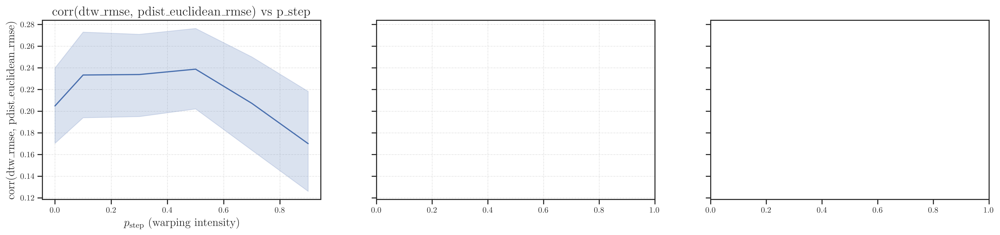

In [20]:
# corr(spi_x, spi_y) vs p_step sweep
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import plot_spi_corr_sweep
from mtsspi.plot_style import apply_plot_style
import matplotlib.pyplot as plt

apply_plot_style()

spi_pairs_sweep = [
    ["dtw_rmse", "pdist_euclidean_rmse"],
    ["xpdist_euclidean_tau-5_min_rmse", "pdist_euclidean_rmse"],
    ["dtw_rmse", "xpdist_euclidean_tau-5_min_rmse"],
]

fig, axes = plt.subplots(1, len(spi_pairs_sweep), figsize=(7 * len(spi_pairs_sweep), 4), squeeze=False, sharey=True, dpi=500)

for ax, spi_pair in zip(axes.flat, spi_pairs_sweep):
    ax.grid(True, which="both", axis="both", lw=0.7, linestyle="--", alpha=0.5)
    plot_spi_corr_sweep(
        project_root() / "data" / "dtw_euclidean" / "260330_lagged-warping_rmse_T1000",
        spi_pair=spi_pair,
        folder_template="lag-10_pstep-<pstep>",
        x_var="pstep",
        metric="pearson",
        hue=False,
        title=rf"corr({spi_pair[0]}, {spi_pair[1]}) vs p_step",
        xlabel=r"$p_{\mathrm{step}}$ (warping intensity)",
        ylabel=rf"$\mathrm{{corr}}$({spi_pair[0]}, {spi_pair[1]})",
        ax=ax,
    )

fig.tight_layout()
plt.show()

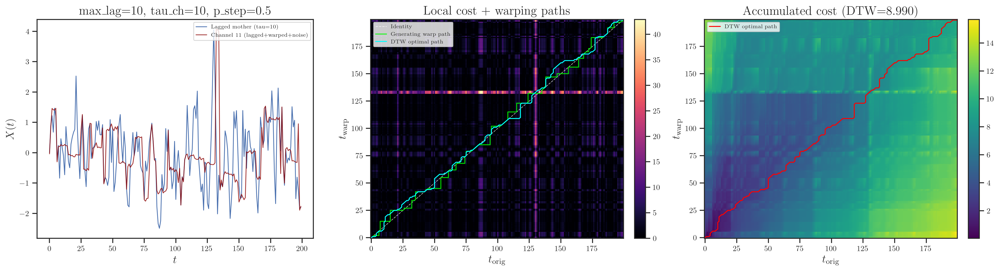

In [ ]:
# Channel-level inspection: lagged + warped signal vs DTW alignment
import mtsspi.generators.linear
importlib.reload(mtsspi.generators.linear)
from mtsspi.generators.linear import generate_lagged_warping_mts
from mtsspi.plot_style import apply_plot_style
from dtaidistance import dtw
import numpy as np
import matplotlib.pyplot as plt

apply_plot_style()

# Generate a short sample for visualization (T=200 keeps cost matrix readable)
M, T = 20, 200
max_lag = 10
p_step = 0.5

data, internals = generate_lagged_warping_mts(
    M=M, T=T, max_lag=max_lag, lag_dist="uniform",
    p_step=p_step, warp_step_dist="uniform", warp_step_max=10,
    noise_std=0.05, noise_std_variable=False,
    ar1_a=0.5, ar1_noise_std=1.0,
    zscore=False,  # keep raw scale for visualization
    rng=42, return_internals=True,
)

# Pick the channel with the largest lag
ch = int(np.argmax(internals.lags))
tau_ch = internals.lags[ch]
actual_max = int(internals.lags.max())
offset = actual_max - tau_ch
lagged_slice = internals.mother[offset : offset + T]
mapping = internals.mappings[ch]

# Noise-free reference: the lagged mother (before warping)
X = np.ascontiguousarray(lagged_slice, dtype=np.double)
# The actual channel output (lagged + warped + noise)
Y = np.ascontiguousarray(data[:, ch], dtype=np.double)

# DTW between the lag-0 reference and this channel
dtw_dist, accum_cost = dtw.warping_paths(X, Y, use_c=True)
path_dtw = np.array(dtw.best_path(accum_cost), dtype=int)
accum_cost_plot = accum_cost[1:, 1:]
local_cost = (X[:, None] - Y[None, :]) ** 2

# Generating warp path (from internals)
path_gen = internals.paths[ch]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=250)

# Panel 1: time series
ax = axes[0]
ax.plot(X, label=f"Lagged mother (tau={tau_ch})", lw=1.0)
ax.plot(Y, label=f"Channel {ch} (lagged+warped+noise)", lw=1.0, alpha=0.8, color="darkred")
ax.set_xlabel(r"$t$")
ax.set_ylabel(r"$X(t)$")
ax.set_title(f"max_lag={max_lag}, tau_ch={tau_ch}, p_step={p_step}")
ax.legend(loc="upper right", fontsize=7)

# Panel 2: local cost matrix + generating warp path + DTW path
ax = axes[1]
im1 = ax.imshow(local_cost.T, origin="lower", aspect="auto", cmap="magma")
ax.plot([0, T - 1], [0, T - 1], "w--", lw=0.8, alpha=0.7, label="Identity")
ax.plot(path_gen[:, 0], path_gen[:, 1], color="lime", lw=1.2, alpha=0.85, label="Generating warp path")
ax.plot(path_dtw[:, 0], path_dtw[:, 1], color="cyan", lw=1.2, label="DTW optimal path")
ax.set_xlabel(r"$t_{\mathrm{orig}}$")
ax.set_ylabel(r"$t_{\mathrm{warp}}$")
ax.set_title("Local cost + warping paths")
ax.legend(loc="upper left", fontsize=7)
fig.colorbar(im1, ax=ax, fraction=0.046, pad=0.04)

# Panel 3: accumulated cost matrix + DTW path
ax = axes[2]
im2 = ax.imshow(accum_cost_plot.T, origin="lower", aspect="auto", cmap="viridis")
ax.plot(path_dtw[:, 0], path_dtw[:, 1], color="red", lw=1.2, label="DTW optimal path")
ax.set_xlabel(r"$t_{\mathrm{orig}}$")
ax.set_ylabel(r"$t_{\mathrm{warp}}$")
ax.set_title(f"Accumulated cost (DTW={dtw_dist:.3f})")
ax.legend(loc="upper left", fontsize=7)
fig.colorbar(im2, ax=ax, fraction=0.046, pad=0.04)

fig.tight_layout()
plt.show()

#### @ Sun 22-Mar: make `T=1000` to keep `dtw` $\leq$ `xpdist_*`

In [46]:
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import (plot_spi_space_individual_embed,
                                plot_spi_space_individual_embed_properties, 
                                plot_spi_space_individual_embed_lags
                                )

from mtsspi.plot_style import apply_plot_style
import matplotlib.pyplot as plt

apply_plot_style()

spi_pairs = [
    ["pdist_euclidean_rmse", "xpdist_euclidean_tau-10_min_rmse"],   # was tau-5, data has tau-4
    ["pdist_euclidean_rmse", "dtw_rmse"],
    ["dtw_rmse", "xpdist_euclidean_tau-10_min_rmse"],
]

# base = "data/dtw_euclidean/260313_lagged/"
base = "data/dtw_euclidean/260322_random-uniform-lag-noise_rmse_T1000/"


datasets = [
    f"{base}/A-1_uniform-lag-noise/M20_T1000_I0",
    f"{base}/A-2_uniform-lag-noise/M20_T1000_I0",
    f"{base}/A-5_uniform-lag-noise/M20_T1000_I0",
    f"{base}/A-20_uniform-lag-noise/M20_T1000_I0",
    f"{base}/A-5_uniform-lag-noise_linspace/M20_T1000_I0",
    f"{base}/A-20_uniform-lag-noise_linspace/M20_T1000_I0"
    # f"{base}/A-1_uniform-lag-noise/M20_T1000_I1",
    # f"{base}/A-2_uniform-lag-noise/M20_T1000_I1",
    # f"{base}/A-5_uniform-lag-noise/M20_T1000_I1",
    # f"{base}/A-20_uniform-lag-noise/M20_T1000_I1",
    # f"{base}/A-5_uniform-lag-noise_linspace/M20_T1000_I1",
    # f"{base}/A-20_uniform-lag-noise_linspace/M20_T1000_I1"

]

n_rows, n_cols = len(datasets), len(spi_pairs)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), 
                        #  sharex="col", sharey="col",
                         squeeze=False, dpi=500)

for r, ds in enumerate(datasets):
    for c, spis in enumerate(spi_pairs):
        plot_spi_space_individual_embed_lags(
            dataset_path=project_root() / ds,
            spis=spis,
            ax=axes[r, c],
            lag_feature="diff",   # |τ_i − τ_j|
            alpha=0.5,
            metric="pearson",
            identity=True
        )

fig.tight_layout(w_pad=7, h_pad=2)
# No shared legend needed — each subplot has its own colorbar
plt.show()


/var/folders/nq/8y70t4y10yb6nq4v5m7p_j340000gp/T/ipykernel_11965/3387940897.py:56: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(w_pad=7, h_pad=2)


#### @ Sun 22-Mar: RMSE normalisation of `xpdist_*` and `pdist_*`

In [38]:
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import (plot_spi_space_individual_embed,
                                plot_spi_space_individual_embed_properties, 
                                plot_spi_space_individual_embed_lags
                                )

from mtsspi.plot_style import apply_plot_style
import matplotlib.pyplot as plt

apply_plot_style()

spi_pairs = [
    ["pdist_euclidean_rmse", "xpdist_euclidean_tau-10_min_rmse"],   # was tau-5, data has tau-4
    ["pdist_euclidean_rmse", "dtw_rmse"],
    ["dtw_rmse", "xpdist_euclidean_tau-10_min_rmse"],
]

# base = "data/dtw_euclidean/260313_lagged/"
base = "data/dtw_euclidean/260322_random-uniform-lag-noise_rmse/"


datasets = [
    f"{base}/A-1_uniform-lag-noise/M20_T100_I0",
    f"{base}/A-2_uniform-lag-noise/M20_T100_I0",
    f"{base}/A-5_uniform-lag-noise/M20_T100_I0",
    f"{base}/A-20_uniform-lag-noise/M20_T100_I0",
    f"{base}/A-5_uniform-lag-noise_linspace/M20_T100_I0",
    f"{base}/A-20_uniform-lag-noise_linspace/M20_T100_I0"
    # f"{base}/A-1_uniform-lag-noise/M20_T100_I1",
    # f"{base}/A-2_uniform-lag-noise/M20_T100_I1",
    # f"{base}/A-5_uniform-lag-noise/M20_T100_I1",
    # f"{base}/A-20_uniform-lag-noise/M20_T100_I1",
    # f"{base}/A-5_uniform-lag-noise_linspace/M20_T100_I1",
    # f"{base}/A-20_uniform-lag-noise_linspace/M20_T100_I1"

]

n_rows, n_cols = len(datasets), len(spi_pairs)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), 
                        #  sharex="col", sharey="col",
                         squeeze=False, dpi=500)

for r, ds in enumerate(datasets):
    for c, spis in enumerate(spi_pairs):
        plot_spi_space_individual_embed_lags(
            dataset_path=project_root() / ds,
            spis=spis,
            ax=axes[r, c],
            lag_feature="diff",   # |τ_i − τ_j|
            alpha=0.6,
            metric="pearson",
            identity=True
        )

fig.tight_layout(w_pad=6, h_pad=2)
# No shared legend needed — each subplot has its own colorbar
plt.show()


/var/folders/nq/8y70t4y10yb6nq4v5m7p_j340000gp/T/ipykernel_11965/1004886609.py:56: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(w_pad=6, h_pad=2)


#### @ Wed-18 Mar: un-lagged, fixed-lagged, variable-lagged. $\tau$ and noise_std uniformly sampled

In [30]:
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import (plot_spi_space_individual_embed,
                                plot_spi_space_individual_embed_properties, 
                                plot_spi_space_individual_embed_lags
                                )

from mtsspi.plot_style import apply_plot_style
import matplotlib.pyplot as plt

apply_plot_style()

spi_pairs = [
    ["pdist_euclidean", "xpdist_euclidean_tau-10_min_rmse"],   # was tau-5, data has tau-4
    ["pdist_euclidean", "dtw"],
    ["dtw", "xpdist_euclidean_tau-10_min_rmse"],
]

# base = "data/dtw_euclidean/260313_lagged/"
base = "data/dtw_euclidean/260318_uniform-lag-noise/"


datasets = [
    f"{base}/A-1_uniform-lag-noise/M16_T100_I0",
    f"{base}/A-2_uniform-lag-noise/M16_T100_I0",
    f"{base}/A-5_uniform-lag-noise/M16_T100_I0",
    f"{base}/A-16_uniform-lag-noise/M16_T100_I0",
    f"{base}/A-5_uniform-lag-noise_linspace/M16_T100_I0",
    f"{base}/A-16_uniform-lag-noise_linspace/M16_T100_I0"
    # f"{base}/A-1_uniform-lag-noise/M16_T100_I1",
    # f"{base}/A-2_uniform-lag-noise/M16_T100_I1",
    # f"{base}/A-5_uniform-lag-noise/M16_T100_I1",
    # f"{base}/A-16_uniform-lag-noise/M16_T100_I1",
    # f"{base}/A-5_uniform-lag-noise_linspace/M16_T100_I1",
    # f"{base}/A-16_uniform-lag-noise_linspace/M16_T100_I1"

]

n_rows, n_cols = len(datasets), len(spi_pairs)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), 
                        #  sharex="col", sharey="col",
                         squeeze=False, dpi=500)

for r, ds in enumerate(datasets):
    for c, spis in enumerate(spi_pairs):
        plot_spi_space_individual_embed_lags(
            dataset_path=project_root() / ds,
            spis=spis,
            ax=axes[r, c],
            lag_feature="diff",   # |τ_i − τ_j|
            alpha=0.6,
            metric="pearson",
            identity=True
        )

fig.tight_layout(w_pad=6, h_pad=2)
# No shared legend needed — each subplot has its own colorbar
plt.show()


/var/folders/nq/8y70t4y10yb6nq4v5m7p_j340000gp/T/ipykernel_11965/2420744036.py:56: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(w_pad=6, h_pad=2)


#### @ Fri-13 Mar: un-lagged, fixed-lagged, variable-lagged

In [21]:
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import (plot_spi_space_individual_embed,
                                plot_spi_space_individual_embed_properties, 
                                plot_spi_space_individual_embed_lags
                                )

from mtsspi.plot_style import apply_plot_style
import matplotlib.pyplot as plt

apply_plot_style()

spi_pairs = [
    ["pdist_euclidean", "xpdist_euclidean_tau-10_min_rmse"],   # was tau-5, data has tau-4
    ["pdist_euclidean", "dtw"],
    ["dtw", "xpdist_euclidean_tau-10_min_rmse"],
]

# base = "data/dtw_euclidean/260313_lagged/"
base = "data/dtw_euclidean/.old-260318/260313_lagged-3/"


datasets = [
    f"{base}un-lagged_A-1/M16_T100_I0",
    # f"{base}un-lagged_A-1/M16_T100_I1",
    f"{base}var-lagged_A-2/M16_T100_I0",
    # f"{base}var-lagged_A-2/M16_T100_I1",
    f"{base}var-lagged_A-5/M16_T100_I0",
    # f"{base}var-lagged_A-5/M16_T100_I1",
    f"{base}lin-lagged_A-5/M16_T100_I0",
    # f"{base}lin-lagged_A-5/M16_T100_I1",
    f"{base}lin-lagged_A-16/M16_T100_I0",
    # f"{base}lin-lagged_A-16/M16_T100_I1",


]

n_rows, n_cols = len(datasets), len(spi_pairs)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), 
                        #  sharex="col", sharey="col",
                         squeeze=False, dpi=500)

for r, ds in enumerate(datasets):
    for c, spis in enumerate(spi_pairs):
        plot_spi_space_individual_embed_lags(
            dataset_path=project_root() / ds,
            spis=spis,
            ax=axes[r, c],
            lag_feature="diff",   # |τ_i − τ_j|
            alpha=0.6,
            metric="pearson"
        )

fig.tight_layout()
# No shared legend needed — each subplot has its own colorbar
plt.show()




/var/folders/nq/8y70t4y10yb6nq4v5m7p_j340000gp/T/ipykernel_11965/3298578124.py:54: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


#### As at 02-Mar

Computed distances:
pdist_euclidean:    1.0654304283836977
dtw:                0.7553544953877916
dtw_sakoe_chiba:    0.7567141879149031


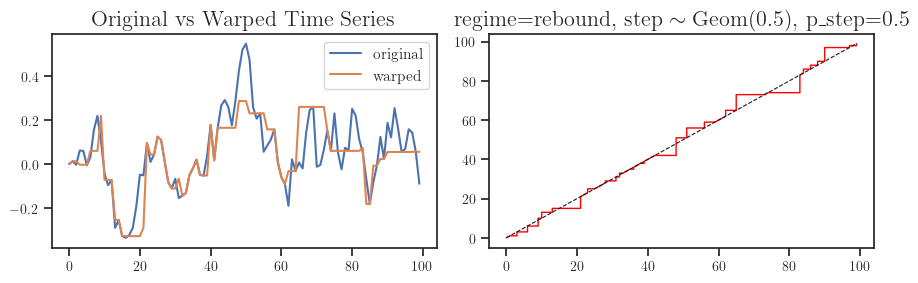

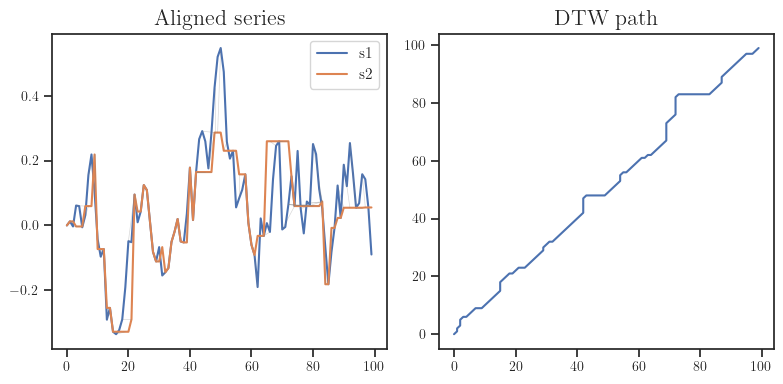

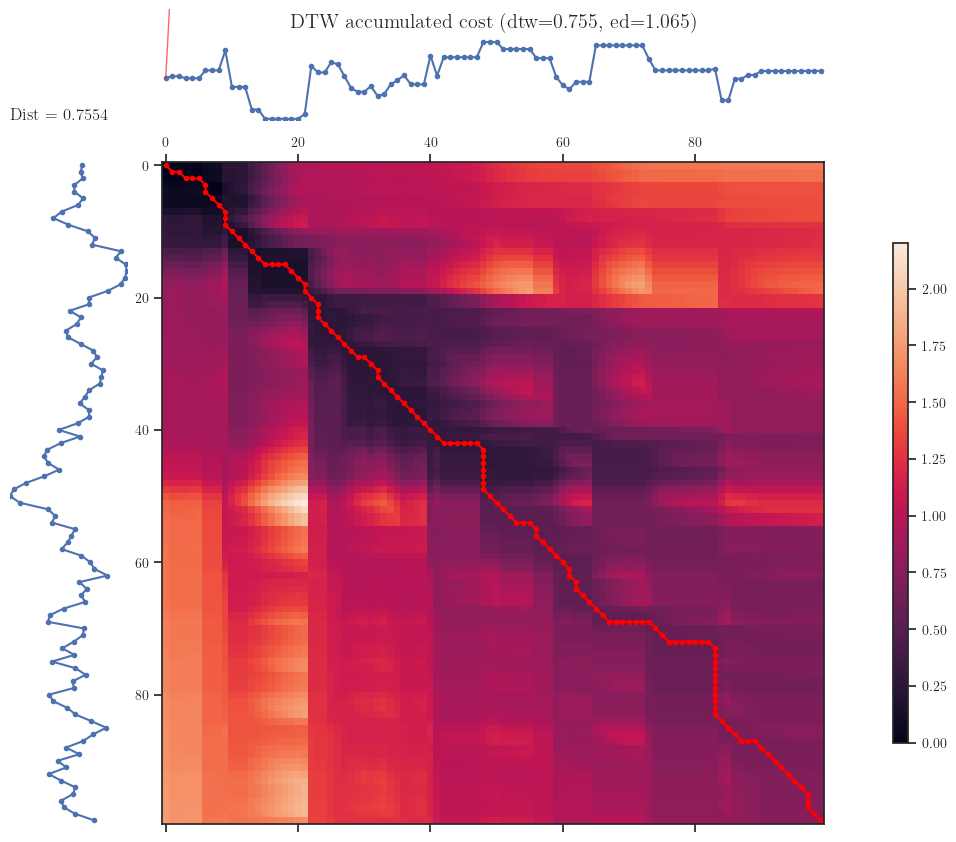

In [22]:
from matplotlib.ticker import ScalarFormatter
import numpy as np
import matplotlib.pyplot as plt
from dtaidistance import dtw, dtw_visualisation as dtwvis
from mtsspi.generators.linear import _warp_path, _path_to_mapping


# --- helpers that no longer exist in src after refactor ---

def generate_ar1(T, a=0.8, noise_std=1.0, seed=None):
    rng = np.random.default_rng(seed)
    x = np.zeros(T)
    for t in range(1, T):
        x[t] = a * x[t - 1] + rng.normal(0, noise_std)
    return x

def warp_path(T, regime, p=0.5, p_step=0.5, step=1, seed=None):
    rng = np.random.default_rng(seed)
    return _warp_path(T, regime, step=step, p=p, p_step=p_step, rng=rng)

def path_to_mapping(path, T):
    return _path_to_mapping(path, T)

def warp_series(X, mapping):
    return X[mapping]

def compute_dtw(s1, s2, use_c=True):
    d, paths = dtw.warping_paths(s1, s2)
    path = dtw.best_path(paths)
    return d, paths, path

def plot_warp(X, X_warp, path_warp, figsize=(9, 3), title_left="", title_right=""):
    fig, axs = plt.subplots(1, 2, figsize=figsize)
    axs[0].plot(X, label="original")
    axs[0].plot(X_warp, label="warped")
    axs[0].legend(); axs[0].set_title(title_left)
    xs, ys = zip(*path_warp)
    axs[1].plot(ys, xs, color="red", linewidth=1)
    axs[1].plot([0, len(X)-1], [0, len(X)-1], "k--", linewidth=0.8)
    axs[1].set_title(title_right)
    fig.tight_layout()
    return fig, axs

def plot_dtw_alignment(s1, s2, path, figsize=(8, 4)):
    fig, axs = plt.subplots(1, 2, figsize=figsize)
    axs[0].plot(s1, label="s1"); axs[0].plot(s2, label="s2")
    axs[0].legend(); axs[0].set_title("Aligned series")
    for i, j in path[::max(1, len(path)//50)]:
        axs[0].plot([i, j], [s1[i], s2[j]], color="gray", alpha=0.3, linewidth=0.5)
    xs, ys = zip(*path)
    axs[1].plot(xs, ys); axs[1].set_title("DTW path")
    fig.tight_layout()
    return fig, axs

def plot_dtw_warping_matrix(s1, s2, paths, path=None, true_path=None,
                             dtw_path_style=None, true_path_style=None,
                             orig_style=None, warp_style=None,
                             title="", cmap="viridis"):
    dtw_path_style  = dtw_path_style  or {"color": "white",  "linewidth": 1.0}
    true_path_style = true_path_style or {"color": "red",    "linewidth": 1.0}
    fig, axes = dtwvis.plot_warpingpaths(
        s1, s2, paths, path=path,
        showlegend=True, figure=None,
    )
    if true_path is not None:
        ax_matrix = axes[1] if hasattr(axes, '__len__') else axes
        tpx, tpy = zip(*true_path)
        ax_matrix.plot(tpy, tpx, **true_path_style)
    if title:
        fig.suptitle(title)
    return fig, axes


# --- main ---

if __name__ == "__main__":
    T = 100
    regime = "rebound"
    p = 0.5
    p_step = 0.5
    noise_std=0.1

    X = generate_ar1(T=T, a=0.8, noise_std=noise_std, seed=0)
    euclidean_vals = []
    dtw_vals = []

    # path_true = warp_path(T=T, regime="geometric", p=p)
    path_warp = warp_path(T=T, regime=regime, p=p, p_step=p_step)
    mapping = path_to_mapping(path_warp, T=T)
    X_warp = warp_series(X, mapping)

    ed = np.linalg.norm(X - X_warp)
    dtw_dist, paths, path_dtw = compute_dtw(X, X_warp, use_c=True)

    euclidean_vals.append(ed)
    dtw_vals.append(dtw_dist)

    print("Computed distances:")
    euclidean = np.linalg.norm(X - X_warp)  # pdist_euclidean
    print(f"pdist_euclidean:    {euclidean}")
    dtw_dist = dtw.distance(X, X_warp, use_c=True)
    print(f"dtw:                {dtw_dist}")
    dtw_sakoe_chiba = dtw.distance(X, X_warp, window=10, use_c=True)
    print(f"dtw_sakoe_chiba:    {dtw_sakoe_chiba}")

    plot_warp(X, X_warp, path_warp, figsize=(9,3),
            title_left=f"Original vs Warped Time Series",
            title_right=rf"regime={regime}, $\mathrm{{step}} \sim \mathrm{{Geom}}({p})$, p_step={p_step}")
    fig_warp, axs_warp = plot_dtw_alignment(X, X_warp, path_dtw, figsize=(8,4))
    fig_paths, axes_paths = plot_dtw_warping_matrix(
        X, X_warp, paths,
        path=path_dtw,
        true_path=path_warp,
        dtw_path_style={"color": "white", "linewidth": 1.0, "marker": "", "alpha": 0.8, "label": "DTW path"},
        true_path_style={"color": "red", "linewidth": 1, "marker": "","alpha": 0.6, "label": "Warping warp"},
        orig_style={"color": "gray",      "linewidth": 1, "alpha": 0.9, "marker": ""},   # → left marginal
        warp_style={"color": "royalblue", "linewidth": 1, "alpha": 0.9, "marker": ""},   # → top marginal
        title=f"DTW accumulated cost (dtw={dtw_dist:.3f}, ed={ed:.3f})",
        # cmap=sns.dark_palette("#b1b4cc", as_cmap=True),
        cmap="viridis"
    )
    plt.show()


###### old plotting

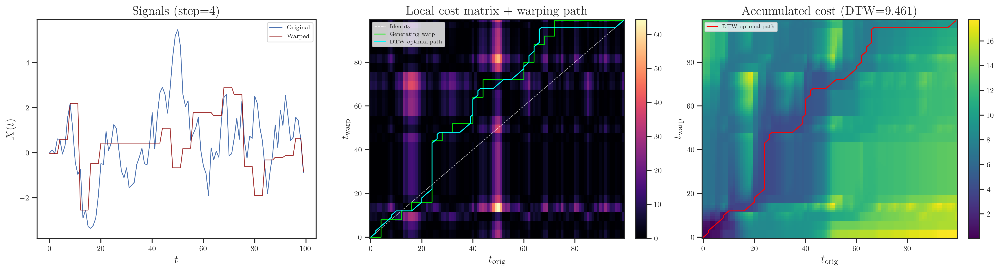

In [23]:
if __name__ == "__main__":
    T = 100
    step = 4

    X = generate_ar1(T=T, a=0.8, noise_std=1.0, seed=0)
    path_true = warp_path(T=T, regime="walk", step=step, seed=42)
    mapping = path_to_mapping(path_true, T=T)
    X_warp = warp_series(X, mapping)

    # Inferred DTW path between X and X_warp
    dtw_dist, accum_cost = dtw.warping_paths(X, X_warp, use_c=True)
    path_dtw = np.array(dtw.best_path(accum_cost), dtype=int)
    accum_cost_plot = accum_cost[1:, 1:]
    local_cost = (X[:, None] - X_warp[None, :]) ** 2

    fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=250)

    # Panel 1: time series
    ax = axes[0]
    ax.plot(X, label="Original", lw=1.0)
    ax.plot(X_warp, label="Warped", lw=1.0, alpha=0.8, color="darkred")
    ax.set_xlabel(r"$t$")
    ax.set_ylabel(r"$X(t)$")
    ax.set_title(f"Signals (step={step})")
    ax.legend(loc="upper right", fontsize=8)

    # Panel 2: classic local cost matrix + paths
    ax = axes[1]
    im1 = ax.imshow(local_cost.T, origin="lower", aspect="auto", cmap="magma")
    ax.plot([0, T - 1], [0, T - 1], "w--", lw=0.8, alpha=0.7, label="Identity")
    ax.plot(path_true[:, 0], path_true[:, 1], color="lime", lw=1.2, alpha=0.85, label="Generating warp")
    ax.plot(path_dtw[:, 0], path_dtw[:, 1], color="cyan", lw=1.2, label="DTW optimal path")
    ax.set_xlabel(rf"$t_{{\mathrm{{orig}}}}$")
    ax.set_ylabel(rf"$t_{{\mathrm{{warp}}}}$")
    ax.set_title("Local cost matrix + warping path")
    ax.legend(loc="upper left", fontsize=7)
    fig.colorbar(im1, ax=ax, fraction=0.046, pad=0.04)

    # Panel 3: accumulated cost matrix + DTW path
    ax = axes[2]
    im2 = ax.imshow(accum_cost_plot.T, origin="lower", aspect="auto", cmap="viridis")
    ax.plot(path_dtw[:, 0], path_dtw[:, 1], color="red", lw=1.2, label="DTW optimal path")
    ax.set_xlabel(rf"$t_{{\mathrm{{orig}}}}$")
    ax.set_ylabel(rf"$t_{{\mathrm{{warp}}}}$")
    ax.set_title(f"Accumulated cost (DTW={dtw_dist:.3f})")
    ax.legend(loc="upper left", fontsize=7)
    fig.colorbar(im2, ax=ax, fraction=0.046, pad=0.04)

    fig.tight_layout()
    plt.show()


###### old DTW Viz

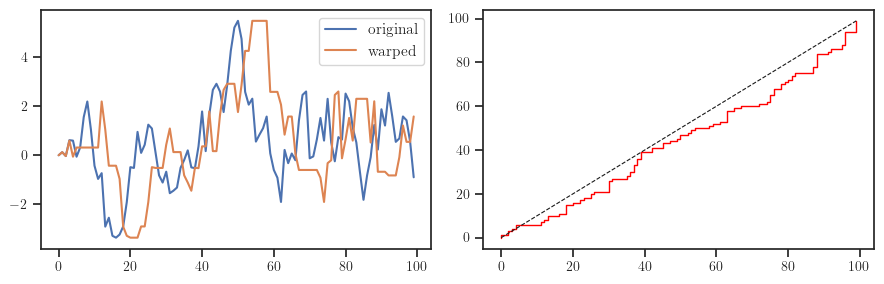

In [24]:
if __name__ == "__main__":
    T = 100
    step = 1

    X = generate_ar1(T=T, a=0.8, noise_std=1.0, seed=0)
    path = warp_path(T=T, regime="walk", step=step, seed=42)
    mapping = path_to_mapping(path, T=T)
    X_warp = warp_series(X, mapping)

    fig, axes = plot_warp(X, X_warp, path)


#### --- divider ---

#### Making the MTS generator

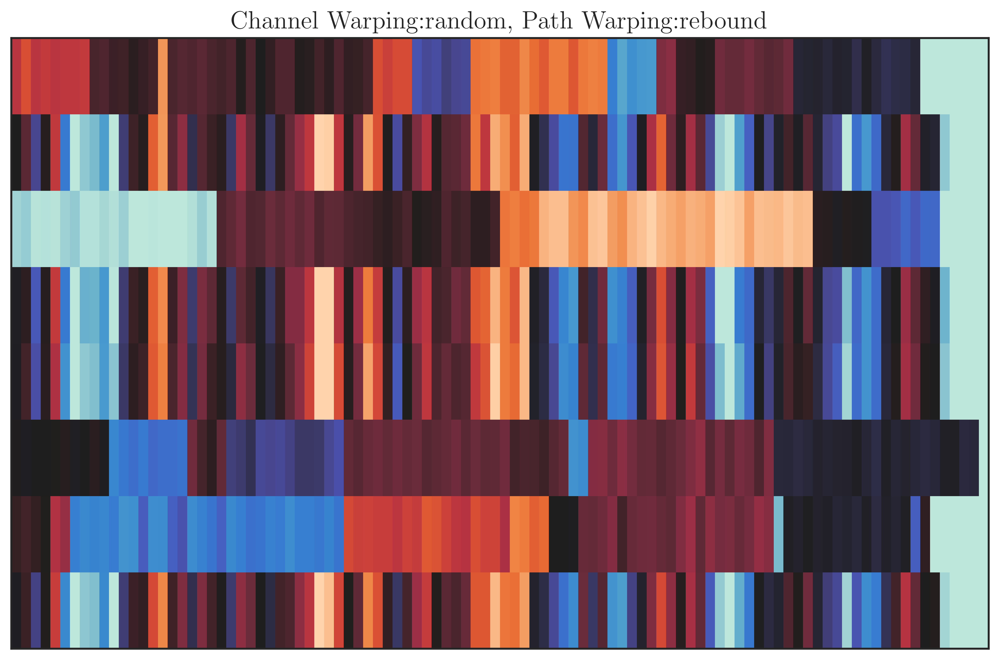

(<Figure size 900x300 with 2 Axes>,
 array([<Axes: title={'center': 'Mother vs Channel 2'}>,
        <Axes: title={'center': 'Warping path — channel 2'}>], dtype=object))

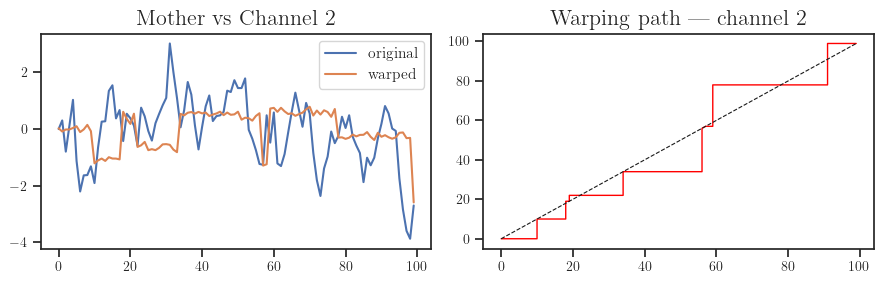

In [25]:
import mtsspi.generators.linear
importlib.reload(mtsspi.generators.linear)
from mtsspi.generators.linear import generate_warping_mts, WarpingInternals

M, T = 8, 100
ar1_a, ar1_noise_std = 0.8, 1.0
n_noisy = 3
n_warped = (M - n_noisy)            # fixed only
warping_channel_regime = "random"
warping_path_regime = "rebound"
warp_p, warp_p_step = 0.1, 0.9       # warp_p: size~Geom(p); warp_p_step: chance of an L-excursion per cycle
noise_std = 0.1

X_random = generate_warping_mts(
    M=M, T=T,
    warping_channel_regime=warping_channel_regime,
    warping_path_regime=warping_path_regime, warp_p=warp_p, warp_p_step=warp_p_step,
    noise_std=noise_std, ar1_a=ar1_a, ar1_noise_std=ar1_noise_std,
    _regime_seed=42, rng=42, return_internals=True
)

# info.mother        → (T,) mother signal
# info.is_warped     → [True/False] per channel
# info.paths[i]      → (n_steps, 2) warping path, or None if channel i is noisy
# info.mappings[i]   → (T,) time-index mapping, or None if channel i is noisy

X_random_plot, info = X_random[0], X_random[1]
# print(info)
plot_mts_heatmap(X_random_plot, title=f"Channel Warping:{warping_channel_regime}, Path Warping:{warping_path_regime}", vmin=-2, vmax=2)

channel = 2
plot_warp(
    info.mother,
    X_random_plot.T[channel],
    info.paths[channel],
    title_left=f"Mother vs Channel {channel}",
    title_right=f"Warping path — channel {channel}",
)

# fig = plt.figure(figsize=(10, 4), dpi=300)
# for i in range(M):
#     plt.plot(X_random_plot.T[i], label=f"Channel {i}", lw=0.6, alpha=0.7)
# plt.plot(info.mother, label="mother", lw=1.0, color="black", linestyle="--")
# plt.legend()

#### Experiment 0.1: M=8, T=100, p=0.5, p_step=0.5

In [26]:
from mtsspi.utils import project_root
import numpy as np
import pandas as pd
from mtsspi.utils import project_root
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import plot_pca, plot_umap, plot_tsne, plot_spi_space_individual, plot_spi_space_recursive

cache = project_root() / "analysis" / "feature_cache" / "data-dtw_euclidean_0.1_spearman.npz"
data  = np.load(cache, allow_pickle=True)
X, y  = data["X"], data["y"]
meta_df = pd.DataFrame({"mts_class": y, "M": data["M"].astype(int), "T": data["T"].astype(int)})

fig, ax = plt.subplots(figsize=(6,6))
# sns.histplot(data=meta_df.assign(corr=X[:, 0]), x="corr", hue="mts_class",
sns.kdeplot(data=meta_df.assign(corr=X[:, 0]), x="corr", hue="mts_class", fill=True, ax=ax)
ax.set_xlabel(r"$\rho$(DTW, Euclidean)")
plt.tight_layout()


plot_spi_space_individual(
    dataset_path=project_root() / "data/dtw_euclidean/dtw_euclidean_0.1/WarpingMTS_Fixed_Rebound_Noisy_Only/M8_T100_I32_m-8_w-0",
    spis=["dtw", "pdist_euclidean"]
) 

plot_spi_space_individual(
    dataset_path=project_root() / "data/dtw_euclidean/dtw_euclidean_0.1/WarpingMTS_Random_Rebound/M8_T100_I32_m-7_w-1",
    spis=["dtw", "pdist_euclidean"]
)

plot_spi_space_individual(
    dataset_path=project_root() / "data/dtw_euclidean/dtw_euclidean_0.1/WarpingMTS_Random_Rebound/M8_T100_I25_m-6_w-2",
    spis=["dtw", "pdist_euclidean"]
)

plot_spi_space_individual(
    dataset_path=project_root() / "data/dtw_euclidean/dtw_euclidean_0.1/WarpingMTS_Random_Rebound/M8_T100_I4_m-4_w-4",
    spis=["dtw", "pdist_euclidean"]
)

plot_spi_space_individual(
    dataset_path=project_root() / "data/dtw_euclidean/dtw_euclidean_0.1/WarpingMTS_Random_Rebound/M8_T100_I20_m-2_w-6",
    spis=["dtw", "pdist_euclidean"]
)

plot_spi_space_individual(
    dataset_path=project_root() / "data/dtw_euclidean/dtw_euclidean_0.1/WarpingMTS_Random_Rebound/M8_T100_I5_m-1_w-7",
    spis=["dtw", "pdist_euclidean"]
) 

plot_spi_space_individual(
    dataset_path=project_root() / "data/dtw_euclidean/dtw_euclidean_0.1/WarpingMTS_Fixed_Rebound_Warped_only/M8_T100_I32_m-0_w-8",
    spis=["dtw", "pdist_euclidean"]
)


FileNotFoundError: [Errno 2] No such file or directory: '/Users/wedi0306/Library/CloudStorage/OneDrive-Personal/Desktop/2025USYD/USYD/mts-spi-study-cluster/analysis/feature_cache/data-dtw_euclidean_0.1_spearman.npz'

#### Experiment 0.2: M=16, T=100, p=0.5, p_step=0.5

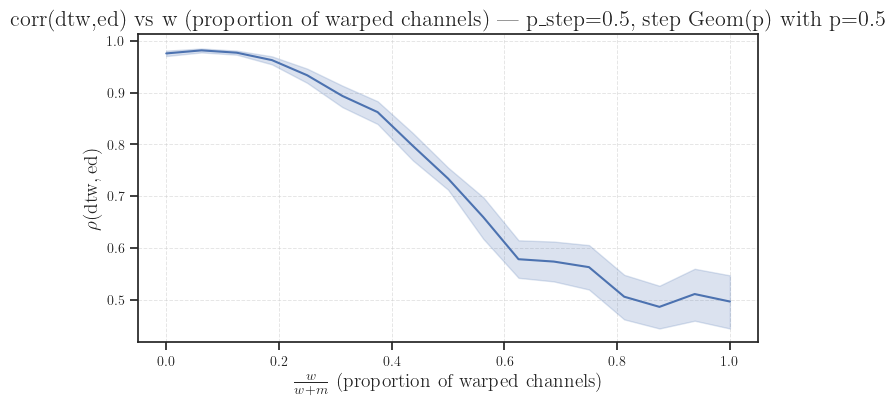

In [ ]:
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import plot_spi_space_individual_embed, plot_spi_corr_sweep
from mtsspi.plot_style import apply_plot_style
import matplotlib.pyplot as plt

apply_plot_style()

spi_pair = ["dtw", "pdist_euclidean"]

fig, axes = plt.subplots(1, 1, figsize=(8, 4), squeeze=False)
plt.grid(True, which="both", axis="both", lw=0.7, linestyle="--", alpha=0.5)
for ax, dataset in zip(axes.flat, ["dtw_euclidean_2.0"]):
    plot_spi_corr_sweep(
    project_root() / "data" / "dtw_euclidean" / "dtw_euclidean_2.0",
    spi_pair=["dtw", "pdist_euclidean"],
    folder_template="m-<m>_w-<w>",
    x_var="w",
    hue=False,
    x_transform=lambda g: g["w"] / (g["m"] + g["w"]),   
    title=rf"corr(dtw,ed) vs w (proportion of warped channels) | p_step=0.5, step~Geom(p) with p=0.5",
    xlabel=r"$\frac{w}{w + m}$ (proportion of warped channels)",
    ylabel=r"$\rho(\mathrm{dtw, ed})$",
    ax=ax,
    )



##### after meeting 24-Feb-2026

In [ ]:
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import plot_spi_space_individual_embed, plot_spi_corr_sweeo
from mtsspi.plot_style import apply_plot_style
import matplotlib.pyplot as plt

apply_plot_style()

spi_pair = ["dtw", "pdist_euclidean"]

fig, axes = plt.subplots(1, 1, figsize=(8, 4), squeeze=False)
for ax, dataset in zip(axes.flat, ["dtw_euclidean_vary-p"]):
    plot_spi_corr_sweep(
    project_root() / "data" / "dtw_euclidean" / "dtw_euclidean_vary-p",
    spi_pair=["dtw", "pdist_euclidean"],
    folder_template="p-<p>",
    hue=False,
    x_var="p",      
    title=rf"corr(dtw,ed) vs p ($\mathrm{{step}} \sim \mathrm{{Geom}}(p)$)",
    xlabel=r"p (lower = larger expected $\mathrm{step}$ size)",
    ylabel=r"$\rho(\mathrm{dtw, ed})$",
    ax=ax,
    )


ImportError: cannot import name 'plot_spi_corr_decay' from 'src.visualization' (/Users/wedi0306/Library/CloudStorage/OneDrive-Personal/Desktop/2025USYD/USYD/mts-spi-study-cluster/src/visualization.py)

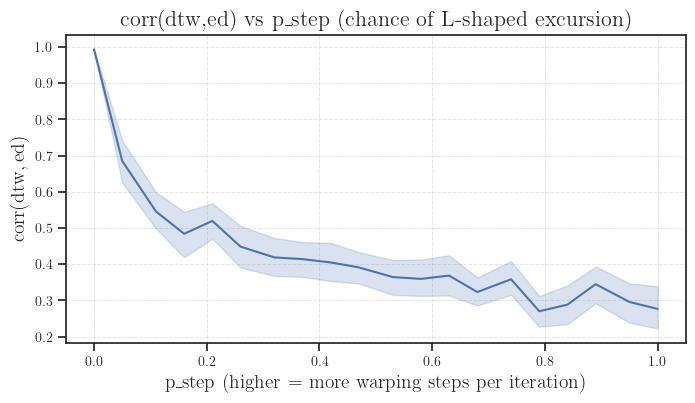

In [ ]:
#placeholder cell for the triple plot 
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import plot_spi_space_individual_embed, plot_spi_corr_decay
from mtsspi.plot_style import apply_plot_style
import matplotlib.pyplot as plt

apply_plot_style()

spi_pair = ["dtw", "pdist_euclidean"]

fig, axes = plt.subplots(1, 1, figsize=(8, 4), squeeze=False)
plt.grid(True, which="both", axis="both", lw=0.7, linestyle="--", alpha=0.5)
for ax, dataset in zip(axes.flat, ["dtw_euclidean_sweep-pstep"]):
    plot_spi_corr_sweep(
    project_root() / "data" / "dtw_euclidean" / "dtw_euclidean_vary-pstep",
    spi_pair=["dtw", "pdist_euclidean"],
    folder_template="pstep-<pstep>",
    hue=False,
    x_var="pstep",
    title=rf"corr(dtw,ed) vs p_step (chance of L-shaped excursion)",
    xlabel="p_step (higher = more warping steps per iteration)",
    ylabel=r"$\mathrm{corr(dtw, ed)}$",
    ax=ax,
)



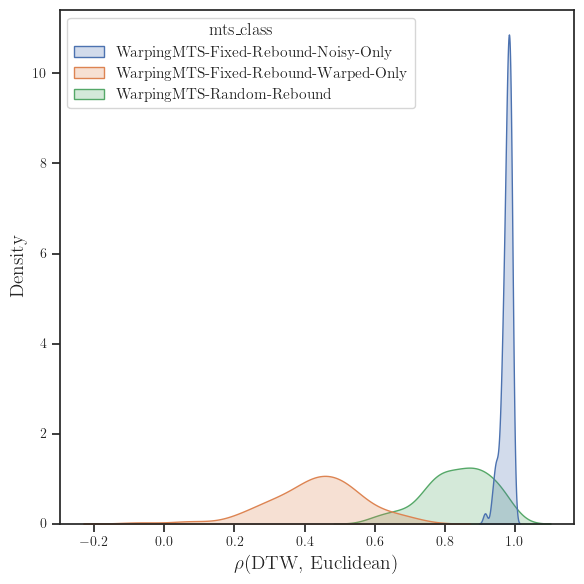

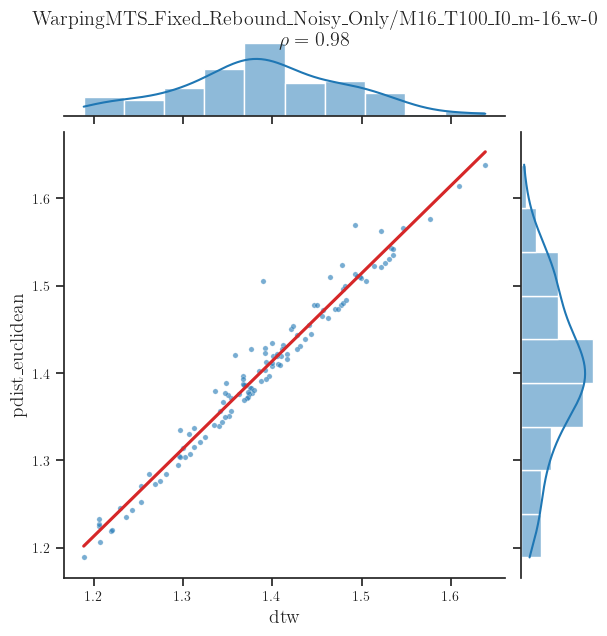

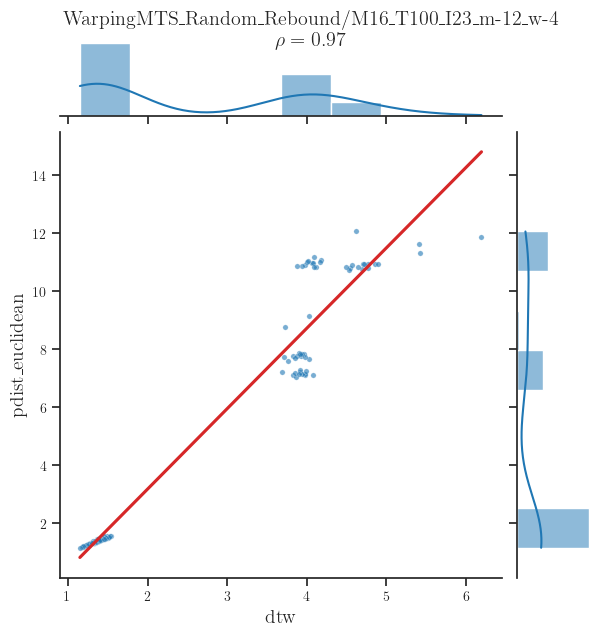

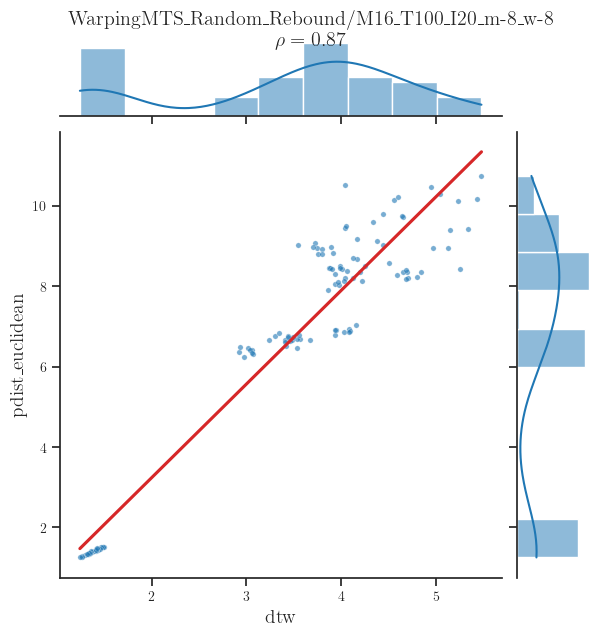

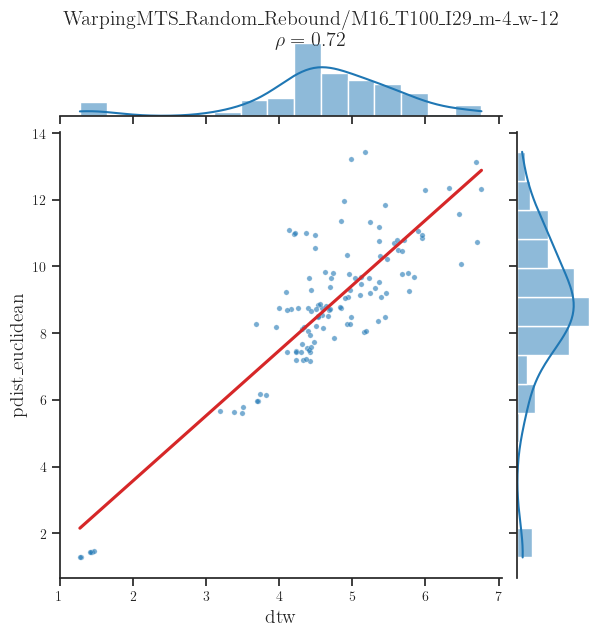

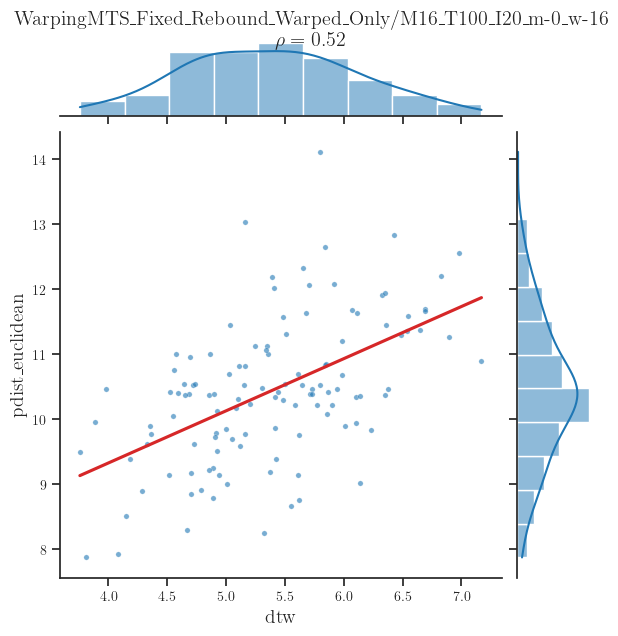

In [ ]:
from mtsspi.utils import project_root
import numpy as np
import pandas as pd
from mtsspi.utils import project_root
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import plot_pca, plot_umap, plot_tsne, plot_spi_space_individual, plot_spi_space_individual_embed, plot_spi_space_recursive
from mtsspi.plot_style import apply_plot_style

apply_plot_style()

cache = project_root() / "analysis" / "feature_cache" / "data-dtw_euclidean_0.2_spearman.npz"
data  = np.load(cache, allow_pickle=True)
X, y  = data["X"], data["y"]
meta_df = pd.DataFrame({"mts_class": y, "M": data["M"].astype(int), "T": data["T"].astype(int)})

fig, ax = plt.subplots(figsize=(6,6))
# sns.histplot(data=meta_df.assign(corr=X[:, 0]), x="corr", hue="mts_class",
sns.kdeplot(data=meta_df.assign(corr=X[:, 0]), x="corr", hue="mts_class", fill=True, ax=ax)
ax.set_xlabel(r"$\rho$(DTW, Euclidean)")
plt.tight_layout()


spi_pairs = [["dtw", "pdist_euclidean"]]
datasets = ["data/dtw_euclidean/dtw_euclidean_0.2/WarpingMTS_Fixed_Rebound_Noisy_Only/M16_T100_I0_m-16_w-0",
            "data/dtw_euclidean/dtw_euclidean_0.2/WarpingMTS_Random_Rebound/M16_T100_I23_m-12_w-4",
            "data/dtw_euclidean/dtw_euclidean_0.2/WarpingMTS_Random_Rebound/M16_T100_I20_m-8_w-8",
            "data/dtw_euclidean/dtw_euclidean_0.2/WarpingMTS_Random_Rebound/M16_T100_I29_m-4_w-12",
            "data/dtw_euclidean/dtw_euclidean_0.2/WarpingMTS_Fixed_Rebound_Warped_Only/M16_T100_I20_m-0_w-16",
            ]

for dataset in datasets:
    for spis in spi_pairs:
        plot_spi_space_individual(dataset_path=project_root() / dataset,spis=spis)

# n_rows, n_cols = len(datasets), len(spi_pairs)
# fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), sharex="col", sharey="col",squeeze=False)

# for r, ds in enumerate(datasets):
#     for c, spis in enumerate(spi_pairs):
#         plot_spi_space_individual_embed(
#             dataset_path=project_root() / ds,
#             spis=spis,
#             ax=axes[r, c],
#             # marginals=False,
#             # marginal_kde=False,
#         )

# fig.tight_layout()
# plt.show()

#### Experiment 1.0: M=16, T=100, p=1, p_step=0.5. 

With $p: 0.5 \to 1.0$, we should expect `pdist_euclidean` to perform better (same expected deviations, less impactful). Therefore, less decoupling than E0.X, across all plots

In [ ]:
from mtsspi.utils import project_root

import numpy as np
import pandas as pd
from mtsspi.utils import project_root
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import plot_pca, plot_umap, plot_tsne, plot_spi_space_individual, plot_spi_space_recursive, plot_spi_space

cache = project_root() / "analysis" / "feature_cache" / "data-dtw_euclidean_1.0_spearman.npz"
data  = np.load(cache, allow_pickle=True)
X, y  = data["X"], data["y"]
meta_df = pd.DataFrame({"mts_class": y, "M": data["M"].astype(int), "T": data["T"].astype(int)})

fig, ax = plt.subplots(figsize=(6,6))
# sns.histplot(data=meta_df.assign(corr=X[:, 0]), x="corr", hue="mts_class",
sns.kdeplot(data=meta_df.assign(corr=X[:, 0]), x="corr", hue="mts_class", fill=True, ax=ax)
ax.set_xlabel(r"$\rho$(DTW, Euclidean)")
plt.tight_layout()


# plot_spi_space_individual(
#     dataset_path=project_root() / "data/dtw_euclidean/dtw_euclidean_1.0/fixed_mother/M16_T100_I0_m-16_w-0",
#     spis=["dtw", "pdist_euclidean"]
# ) 

# plot_spi_space_individual(
#     dataset_path=project_root() / "data/dtw_euclidean/dtw_euclidean_1.0/random_mixed/M16_T100_I33_m-12_w-4",
#     spis=["dtw", "pdist_euclidean"]
# )

# plot_spi_space_individual(
#     dataset_path=project_root() / "data/dtw_euclidean/dtw_euclidean_1.0/random_mixed/M16_T100_I22_m-8_w-8",
#     spis=["dtw", "pdist_euclidean"]
# )

# plot_spi_space_individual(
#     dataset_path=project_root() / "data/dtw_euclidean/dtw_euclidean_1.0/random_mixed/M16_T100_I0_m-4_w-12",
#     spis=["dtw", "pdist_euclidean"]
# )

# plot_spi_space_individual(
#     dataset_path=project_root() / "data/dtw_euclidean/dtw_euclidean_1.0/fixed_warped/M16_T100_I20_m-0_w-16",
#     spis=["dtw", "pdist_euclidean"]
# )

spi_pairs = [["dtw", "pdist_euclidean"]]
datasets = ["data/dtw_euclidean/dtw_euclidean_1.0/fixed_mother/M16_T100_I0_m-16_w-0",
            "data/dtw_euclidean/dtw_euclidean_1.0/random_mixed/M16_T100_I33_m-12_w-4",
            "data/dtw_euclidean/dtw_euclidean_1.0/random_mixed/M16_T100_I22_m-8_w-8",
            "data/dtw_euclidean/dtw_euclidean_1.0/random_mixed/M16_T100_I0_m-4_w-12",
            "data/dtw_euclidean/dtw_euclidean_1.0/fixed_warped/M16_T100_I20_m-0_w-16",
            ]   

n_rows, n_cols = len(datasets), len(spi_pairs)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), sharex="col", sharey="col",squeeze=False)    
for r, ds in enumerate(datasets):
    for c, spis in enumerate(spi_pairs):
        plot_spi_space_individual(
            dataset_path=project_root() / ds,
            spis=spis,
            ax=axes[r, c],
            # marginals=False,
            # marginal_kde=False,
        )


ImportError: cannot import name 'plot_spi_space' from 'src.visualization' (/Users/wedi0306/Library/CloudStorage/OneDrive-Personal/Desktop/2025USYD/USYD/mts-spi-study-cluster/src/visualization.py)

#### Experiment 1.1: M=16, T=100, p=1.0, p_step=0.1 
$p_{\mathrm{step}}: 0.5 \to 0.1$ -> low step magnitude, low chance of step = more where `pdist_euclidean` and `dtw` should become clearer, i.e., the `random-mixed` tag should be closer to `fixed-mother`)

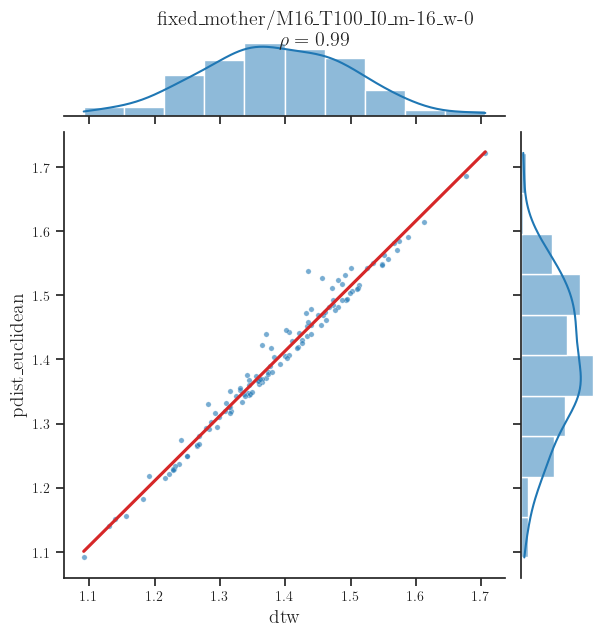

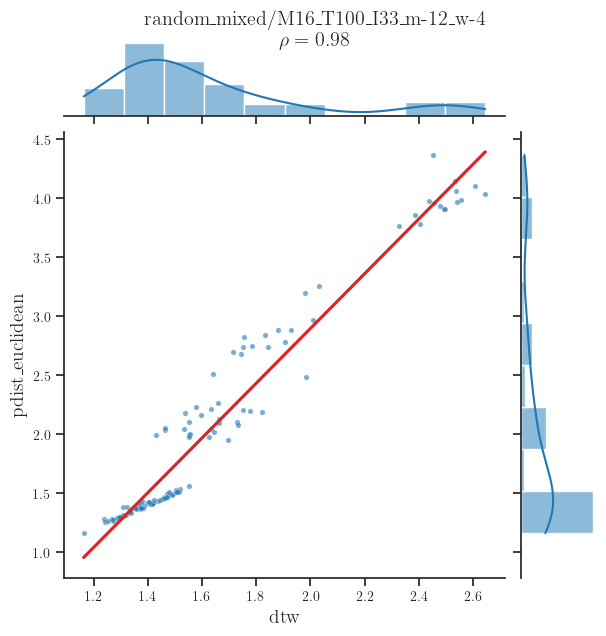

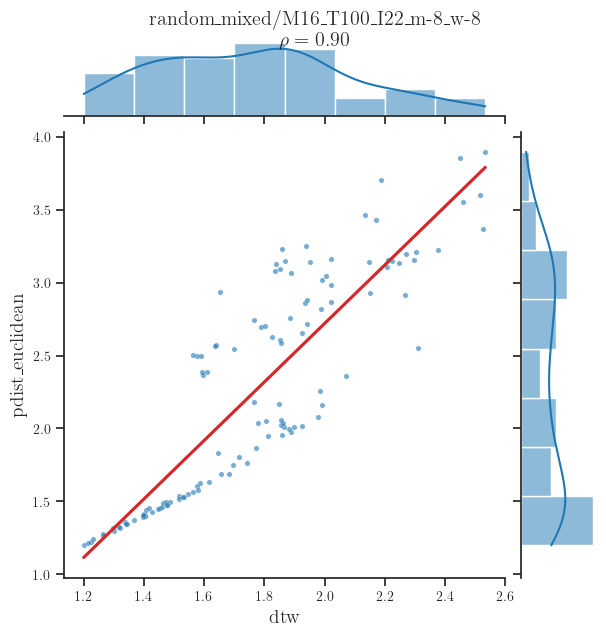

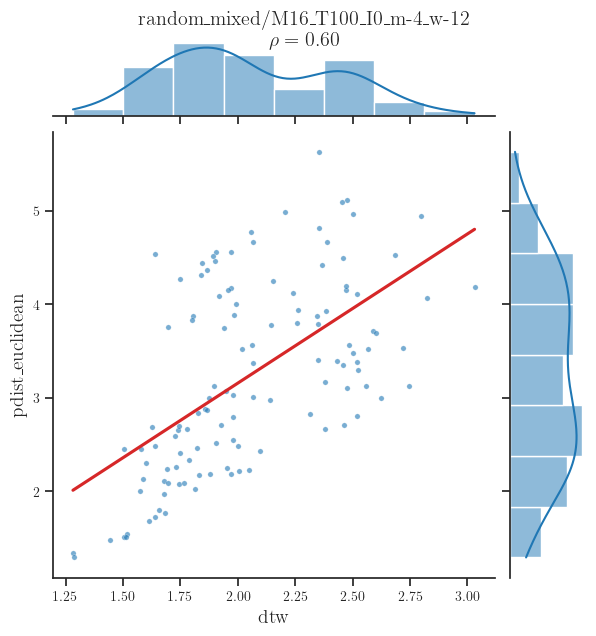

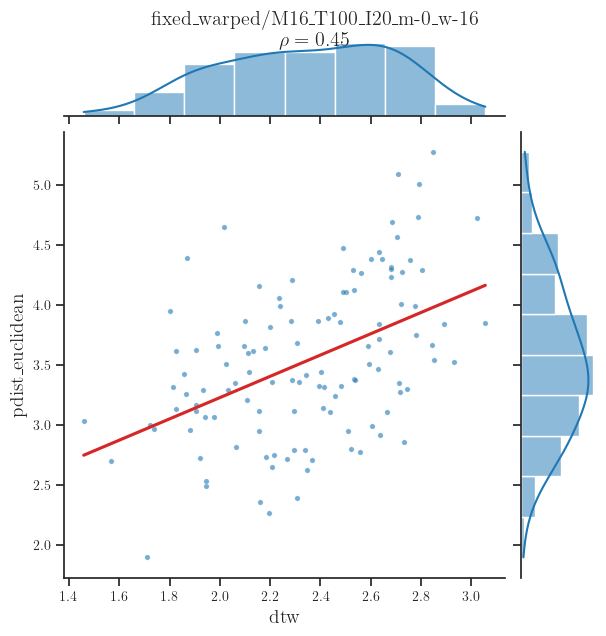

In [ ]:
from mtsspi.utils import project_root

import numpy as np
import pandas as pd
from mtsspi.utils import project_root
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import plot_pca, plot_umap, plot_tsne, plot_spi_space_individual, plot_spi_space_recursive

cache = project_root() / "analysis" / "feature_cache" / "data-dtw_euclidean_1.1_spearman.npz"
data  = np.load(cache, allow_pickle=True)
X, y  = data["X"], data["y"]
meta_df = pd.DataFrame({"mts_class": y, "M": data["M"].astype(int), "T": data["T"].astype(int)})

fig, ax = plt.subplots(figsize=(6,6))
# sns.histplot(data=meta_df.assign(corr=X[:, 0]), x="corr", hue="mts_class",
sns.kdeplot(data=meta_df.assign(corr=X[:, 0]), x="corr", hue="mts_class", fill=True, ax=ax)
ax.set_xlabel(r"$\rho$(DTW, Euclidean)")
plt.tight_layout()



plot_spi_space_individual(
    dataset_path=project_root() / "data/dtw_euclidean_1.1/fixed_mother/M16_T100_I0_m-16_w-0",
    spis=["dtw", "pdist_euclidean"]
) 

plot_spi_space_individual(
    dataset_path=project_root() / "data/dtw_euclidean_1.1/random_mixed/M16_T100_I33_m-12_w-4",
    spis=["dtw", "pdist_euclidean"]
)

plot_spi_space_individual(
    dataset_path=project_root() / "data/dtw_euclidean_1.1/random_mixed/M16_T100_I22_m-8_w-8",
    spis=["dtw", "pdist_euclidean"]
)

plot_spi_space_individual(
    dataset_path=project_root() / "data/dtw_euclidean_1.1/random_mixed/M16_T100_I0_m-4_w-12",
    spis=["dtw", "pdist_euclidean"]
)

plot_spi_space_individual(
    dataset_path=project_root() / "data/dtw_euclidean_1.1/fixed_warped/M16_T100_I20_m-0_w-16",
    spis=["dtw", "pdist_euclidean"]
)

# plot_spi_space_individual(
#     dataset_path=project_root() / "data/dtw_euclidean_0.1/WarpingMTS_Random_Rebound/M8_T100_I5_m-1_w-7",
#     spis=["dtw", "pdist_euclidean"]
# ) 

# plot_spi_space_individual(
#     dataset_path=project_root() / "data/dtw_euclidean_0.1/WarpingMTS_Fixed_Rebound_Warped_only/M8_T100_I32_m-0_w-8",
#     spis=["dtw", "pdist_euclidean"]
# )


#### Experiment 1.2: M=16, T=100, p=0.1, p_step=0.9 
$p_{\mathrm{step}}: 0.5 \to 1.0$ -> high step magnitude, high chance of step = more where `pdist_euclidean` and `dtw` should become clearer, i.e., the `random-mixed` tag is likely closer to `fixed-warped`))

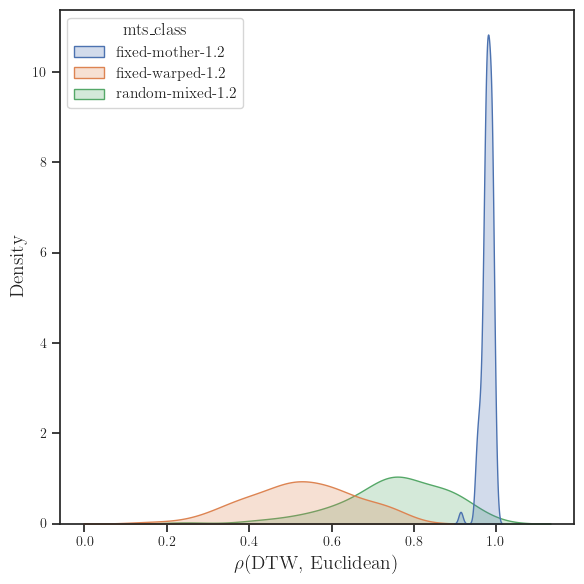

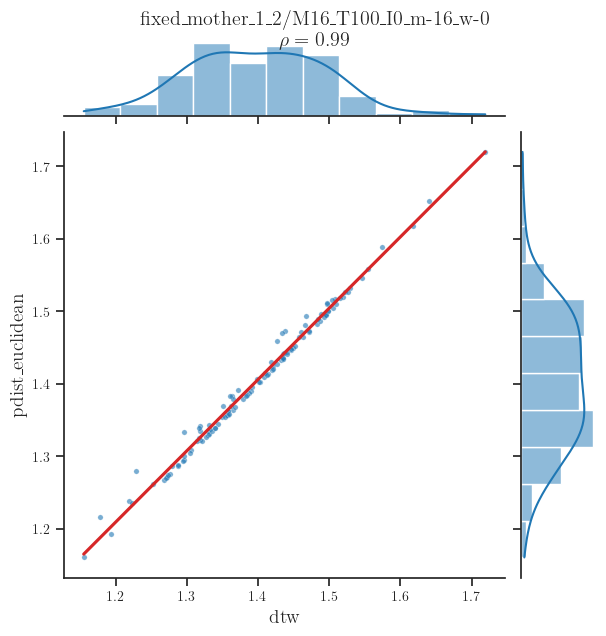

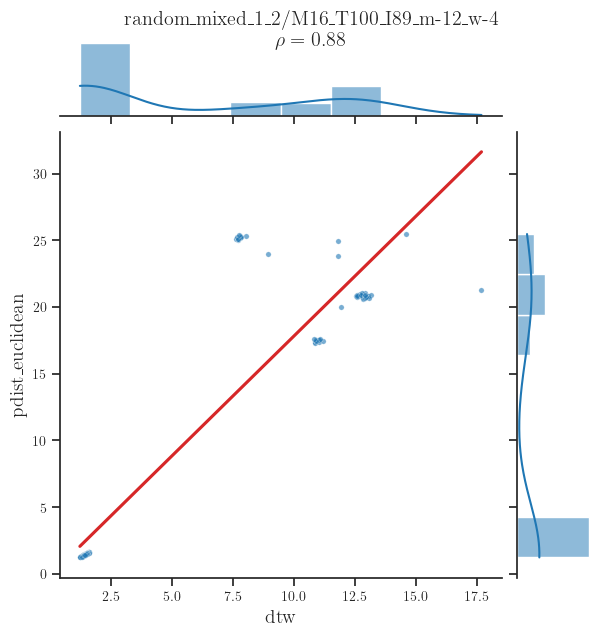

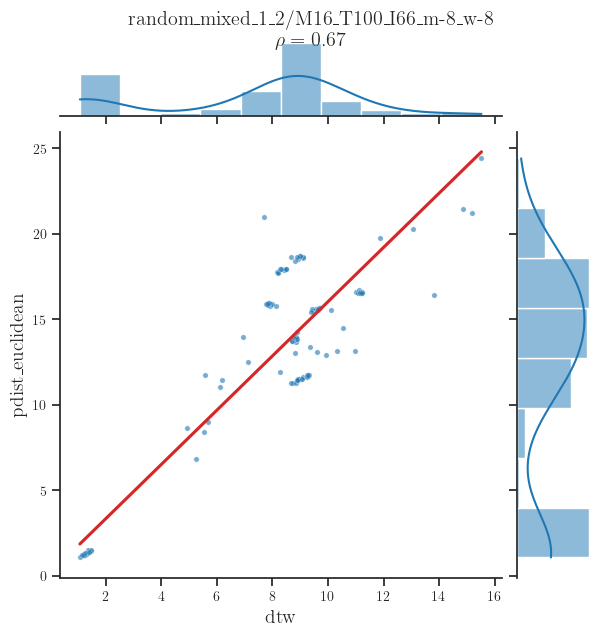

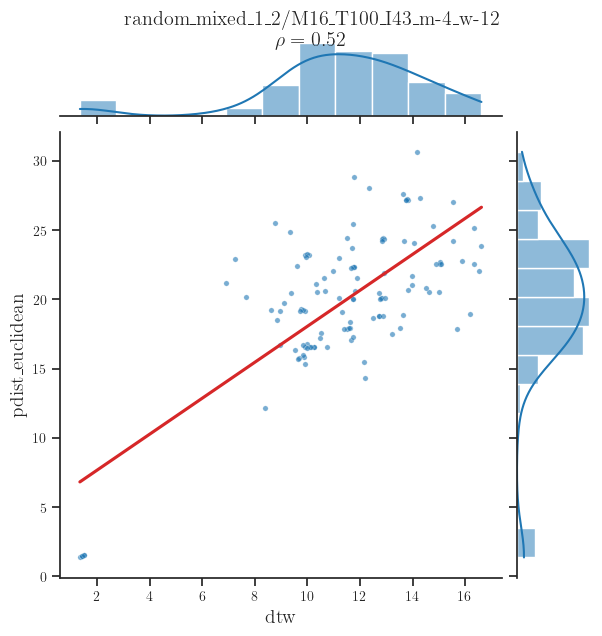

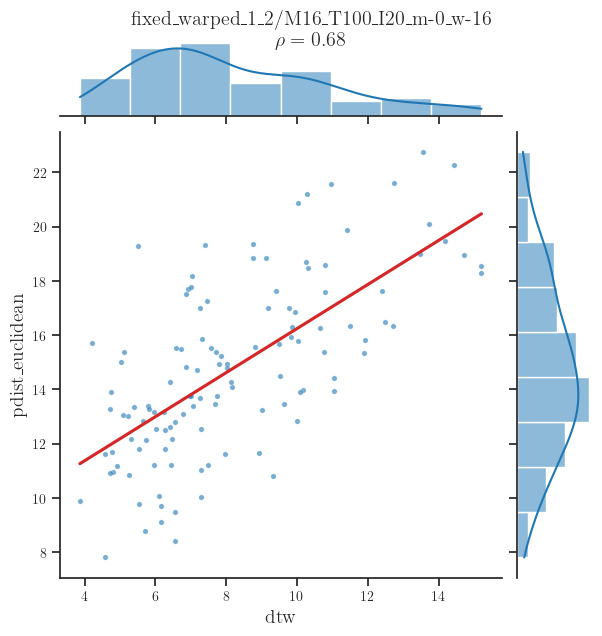

In [ ]:
from mtsspi.utils import project_root

import numpy as np
import pandas as pd
from mtsspi.utils import project_root
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import plot_pca, plot_umap, plot_tsne, plot_spi_space_individual, plot_spi_space_recursive

cache = project_root() / "analysis" / "feature_cache" / "data-dtw_euclidean_1.2_spearman.npz"
data  = np.load(cache, allow_pickle=True)
X, y  = data["X"], data["y"]
meta_df = pd.DataFrame({"mts_class": y, "M": data["M"].astype(int), "T": data["T"].astype(int)})

fig, ax = plt.subplots(figsize=(6,6))
# sns.histplot(data=meta_df.assign(corr=X[:, 0]), x="corr", hue="mts_class",
sns.kdeplot(data=meta_df.assign(corr=X[:, 0]), x="corr", hue="mts_class", fill=True, ax=ax)
ax.set_xlabel(r"$\rho$(DTW, Euclidean)")
plt.tight_layout()



plot_spi_space_individual(
    dataset_path=project_root() / "data/dtw_euclidean_1.2/fixed_mother_1_2/M16_T100_I0_m-16_w-0",
    spis=["dtw", "pdist_euclidean"]
) 

plot_spi_space_individual(
    dataset_path=project_root() / "data/dtw_euclidean_1.2/random_mixed_1_2/M16_T100_I89_m-12_w-4",
    spis=["dtw", "pdist_euclidean"]
)

plot_spi_space_individual(
    dataset_path=project_root() / "data/dtw_euclidean_1.2/random_mixed_1_2/M16_T100_I66_m-8_w-8",
    spis=["dtw", "pdist_euclidean"]
)

plot_spi_space_individual(
    dataset_path=project_root() / "data/dtw_euclidean_1.2/random_mixed_1_2/M16_T100_I43_m-4_w-12",
    spis=["dtw", "pdist_euclidean"]
)

plot_spi_space_individual(
    dataset_path=project_root() / "data/dtw_euclidean_1.2/fixed_warped_1_2/M16_T100_I20_m-0_w-16",
    spis=["dtw", "pdist_euclidean"]
)

# plot_spi_space_individual(
#     dataset_path=project_root() / "data/dtw_euclidean_0.1/WarpingMTS_Random_Rebound/M8_T100_I5_m-1_w-7",
#     spis=["dtw", "pdist_euclidean"]
# ) 

# plot_spi_space_individual(
#     dataset_path=project_root() / "data/dtw_euclidean_0.1/WarpingMTS_Fixed_Rebound_Warped_only/M8_T100_I32_m-0_w-8",
#     spis=["dtw", "pdist_euclidean"]
# )


#### End header